# 05 - 1 MNQ plus a semis short

**TL;DR** (data through 2026-11-20; MNQ margin assumed as in 04)
- **Idea:** short 1 MNQ, hold more NVDA, and add a semis short to take out the AI/semis
  risk the NDX hedge leaves. Pick the semis short with a penalty on gross, NVDA sized to
  a \$10k monthly VaR.
- **Today it doesn't pay.** Net of NDX, NVDA's semis beta is about 0 (-0.07 to +0.04 on
  126-504 days for the clean legs; SMH shows 0.47 only because it is 20% NVDA). With
  1 MNQ, about 98% of the remaining risk is already NVDA-specific. The optimal semis
  short is about \$1k at any lambda, and `L` stays at about **\$35k** whatever you add.
- **Recommended today: 1 MNQ + ~\$35k NVDA in cash, no semis short.** Capital is about
  \$39k (\$35.3k NVDA + \$3.6k MNQ margin). Net carry is about +\$0.4k a year.
- **History agrees:** with the same lambda refit monthly, the overlay shorted \$41-46k
  of semis on average (semis beta was higher in 2020-23). That let `L` grow to
  \$55-61k, but Sharpe fell from 1.09 to 0.74-0.81 and max drawdown went from \$27k to
  \$49k. It cut the book's correlation with the semis factor from 0.19 to about -0.09,
  but over-hedged it (-0.2 to -0.4) in 2026.
- No liquid semis future exists that I know of (unverified), so any semis leg means
  borrowing ETF shares or stocks.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from nvai import hedge as hg
from nvai.config import FIGURES, settings
from nvai.data import load

warnings.filterwarnings("ignore", category=FutureWarning)


def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png")
    plt.show()

pd.set_option("display.width", 160, "display.float_format", lambda v: f"{v:,.2f}")
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
INK2, GRID = "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": INK2,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "legend.frameon": False, "font.size": 9,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

# Same assumptions as 04
MULT, MM = 2.0, 3_300
IM = 1.10 * MM
QQQ_ER, TICK, COMM = 0.0020, 0.25 * 2.0, 1.00
TCOST_STOCK, VAR_TARGET, ANN, M = 0.0010, 10_000, 252, 21

ret = load.returns()
rf = load.risk_free().reindex(ret.index).ffill()
fees = load.borrow_fees(fill_default=True).reindex(ret.index).ffill()
fut = pd.read_parquet(load.raw_dir("free") / "ndx_futures.parquet").set_index("date")
ndx = fut["NDX"].reindex(ret.index).ffill()
C_t = (MULT * ndx).shift(1)                          # contract notional known at open
C_now = MULT * ndx.iat[-1]
w_nv = load.nvda_weight().reindex(ret.index).ffill().shift(1)

xn = ret.NVDA - rf
f = ret.QQQ + QQQ_ER / ANN - rf                      # fair-value NDX futures return

# Semis legs: daily total return, borrow fee, NVDA weight inside the leg
semis_names = settings()["baskets"]["semis_ex_nvda"]
LEGS = {
    "SMH": {"r": ret.SMH, "fee": fees.SMH, "w": w_nv.SMH},
    "SOXX": {"r": ret.SOXX, "fee": fees.SOXX, "w": w_nv.SOXX},
    "semis_ex_nvda (EW)": {"r": hg.ew_monthly_basket(ret[semis_names]).reindex(ret.index),
                               "fee": fees[semis_names].mean(axis=1), "w": pd.Series(0.0, ret.index)},
    # not directly tradeable: short SMH and buy back w/(1-w) of NVDA to strip NVDA out
    "SMH ex-NVDA": {"r": (ret.SMH - w_nv.SMH * ret.NVDA) / (1 - w_nv.SMH),
                        "fee": fees.SMH / (1 - w_nv.SMH), "w": pd.Series(0.0, ret.index)},
}
for v in LEGS.values():
    v["x"] = v["r"] - rf

## 1. Two-factor model

`NVDA = a + b_ndx x NDX + b_semi x semis_perp + e`, where `semis_perp` is the semis leg
with its NDX part removed (regressed on NDX futures, same window). So `b_ndx` is the
same beta as in 04, and `b_semi` is the extra, semis-specific exposure.

`b_semi > 0` means NVDA still carries semis risk after the NDX hedge. The semis short
also carries NDX (`c`), so with a semis short, 1 MNQ covers more NVDA. All betas are
shrunk 50/50 (trailing 252 days and full sample). This section is context; the sizing
in section 2 works directly on covariances.

In [2]:
def shrunk_betas(x_leg):
    t = hg.two_factor_betas(xn, f, x_leg, 252)
    full = hg.two_factor_betas(xn, f, x_leg, None)
    s = 0.5 * t[["b_f", "b_s", "c"]] + 0.5 * full[["b_f", "b_s", "c"]]
    s["f_hedge"] = s.b_f - s.b_s * s.c
    return s


B = {k: shrunk_betas(v["x"]) for k, v in LEGS.items()}
today = pd.DataFrame({k: b.iloc[-1] for k, b in B.items()}).T
today.columns = ["b_ndx", "b_semi", "c (leg's NDX beta)", "NDX hedge per $ NVDA"]
today

,b_ndx,b_semi,c (leg's NDX beta),NDX hedge per $ NVDA
SMH,1.47,0.66,1.58,0.42
SOXX,1.47,0.26,1.72,1.02
semis_ex_nvda (EW),1.47,0.15,1.79,1.20
SMH ex-NVDA,1.47,0.16,1.63,1.21


Light robustness on `b_semi` (unshrunk, ending today):

In [3]:
def static(y, ff, s):
    return hg.two_factor_betas(y, ff, s, window=len(y), min_periods=len(y) - 5).iloc[-1]


def weekly(s):
    return (1 + s).resample("W-FRI").prod() - 1


rob = {}
for k, v in LEGS.items():
    r = {f"daily {n}d": static(xn.iloc[-n:], f.iloc[-n:], v["x"].iloc[-n:]).b_s
         for n in (126, 252, 504)}
    sl = slice(-252, None)
    wk = [weekly(s.iloc[sl] + rf.iloc[sl]) - weekly(rf.iloc[sl]) for s in (xn, f, v["x"])]
    r["weekly 52 wks"] = static(*[s.dropna() for s in wk]).b_s
    r["full sample"] = B[k].iloc[-1].b_s * 2 - hg.two_factor_betas(
        xn, f, v["x"], 252).iloc[-1].b_s  # recover full-sample piece of the shrunk value
    r["shrunk (used)"] = B[k].iloc[-1].b_s
    rob[k] = r
pd.DataFrame(rob)

,SMH,SOXX,semis_ex_nvda (EW),SMH ex-NVDA
daily 126d,0.48,0.01,-0.07,-0.07
daily 252d,0.47,0.02,-0.05,-0.06
daily 504d,0.63,0.07,0.04,0.00
weekly 52 wks,0.36,-0.02,-0.11,-0.13
full sample,0.85,0.50,0.36,0.37
shrunk (used),0.66,0.26,0.15,0.16


**Semis futures?** I'm not aware of a liquid listed semiconductor index future (no
active SOX contract; CME's sector futures don't include semis). I couldn't check
CME's site from here, so treat that as unverified. The semis leg has to be a short in
ETF shares or stocks.

## 2. Adding the semis short, with a penalty on gross

**Fixed:** 1 MNQ short (`M` = contract notional, about \$50.1k).
**Chosen:** NVDA long `L` (cash) and semis short `S >= 0`.

- **Size:** `L` is always set so the book's monthly 99% VaR is \$10k, using the EWMA
  covariance (lambda 0.94, x sqrt 21) as in 03-04.
- **What we want to keep:** NVDA-specific risk. A common factor model splits NVDA into
  NDX futures + semis (semis_ex_nvda, which has no NVDA in it) + an NVDA-specific
  residual. The NVDA-specific \$ exposure is `L - w*S`, where `w` is the NVDA weight
  inside the semis leg (SMH ~20%, SOXX ~8%, 0 for the others).
- **Objective:** choose `S` to minimize
  `(non-NVDA-specific share of book variance) + lambda x (gross / $100k)^2`,
  with gross = `L + M + S`. Covariances are shrunk 50/50 (trailing 252 days and full
  sample).
- `lambda = 0` hedges semis risk as fully as possible. `lambda -> inf` drives `S` to 0,
  which is the 04 MNQ-only book (VaR-sized).

Because VaR is fixed, a cleaner hedge leaves more room for NVDA (`L` grows), and the
penalty stops gross from growing too far.

In [4]:
s_clean = hg.ew_monthly_basket(ret[semis_names]).reindex(ret.index) - rf
LAMBDAS = [0, 0.003, 0.01, 0.03, 0.1, 0.3, 1, np.inf]
S_GRID = np.arange(0, 200_001, 500.0)


def covs_at(k, end):
    """(EWMA cov, shrunk cov) of [NVDA, NDX fut, leg], plus NVDA-specific variance, at `end`."""
    X = pd.concat([xn, f, LEGS[k]["x"], s_clean], axis=1, keys=["n", "f", "l", "s"]).loc[:end]
    X = X.dropna()
    ew = X[["n", "f", "l"]].ewm(alpha=0.06).cov().loc[X.index[-1]].to_numpy()
    sh = 0.5 * X.iloc[-252:].cov().to_numpy() + 0.5 * X.cov().to_numpy()
    fac = [1, 3]                                   # NDX fut, clean semis factor
    b = np.linalg.solve(sh[np.ix_(fac, fac)], sh[fac, 0])
    sig_eps2 = sh[0, 0] - sh[0, fac] @ b
    return ew, sh[:3, :3], sig_eps2


def frontier(k, end, M_):
    """For every S on the grid: L at $10k VaR, gross, and the risk split."""
    ew, sh, se2 = covs_at(k, end)
    w = LEGS[k]["w"].loc[:end].dropna()
    w = w.iat[-1] if len(w) else 0.0
    S = S_GRID
    V = (VAR_TARGET / (hg.Z99 * np.sqrt(M))) ** 2              # allowed daily variance
    a = ew[0, 0]
    b = -2 * (M_ * ew[0, 1] + S * ew[0, 2])
    c = M_ ** 2 * ew[1, 1] + 2 * M_ * S * ew[1, 2] + S ** 2 * ew[2, 2] - V
    disc = np.maximum(b ** 2 - 4 * a * c, 0)
    L = (-b + np.sqrt(disc)) / (2 * a)
    var_sh = (L ** 2 * sh[0, 0] + M_ ** 2 * sh[1, 1] + S ** 2 * sh[2, 2]
              - 2 * L * M_ * sh[0, 1] - 2 * L * S * sh[0, 2] + 2 * M_ * S * sh[1, 2])
    spec = (L - w * S) ** 2 * se2
    out = pd.DataFrame({"S": S, "L": L, "gross": L + M_ + S, "net": L - M_ - S,
                        "nvda_spec_vol": np.sqrt(ANN * spec),
                        "other_vol": np.sqrt(ANN * np.maximum(var_sh - spec, 0)),
                        "other_share": np.maximum(var_sh - spec, 0) / var_sh, "w": w})
    return out[(b ** 2 - 4 * a * c > 0) & (L > 0)]          # S with a valid $10k-VaR L


def pick(fr, lam):
    if np.isinf(lam):
        return fr.iloc[0]
    return fr.iloc[(fr.other_share + lam * (fr.gross / 1e5) ** 2).argmin()]


def knee(fr):
    """Point of the S-grid curve farthest from the chord between S=0 and the lambda=0 point."""
    end = pick(fr, 0).name
    seg = fr.loc[:end]
    if len(seg) < 3:
        return seg.iloc[0]
    x = (seg.gross - seg.gross.iat[0]) / (seg.gross.iat[-1] - seg.gross.iat[0])
    y = (seg.other_vol - seg.other_vol.iat[-1]) / (seg.other_vol.iat[0] - seg.other_vol.iat[-1])
    return seg.iloc[(1 - x - y).abs().argmax()]


end = ret.index[-1]
FR = {k: frontier(k, end, C_now) for k in LEGS}
KNEE_LAM = {}
for k, fr in FR.items():
    kn = knee(fr)
    KNEE_LAM[k] = min(LAMBDAS, key=lambda lam: abs(pick(fr, lam).S - kn.S))

leg_rows = []
for k, fr in FR.items():
    p = pick(fr, KNEE_LAM[k])
    leg_rows.append({"semis leg": k, "knee lambda": KNEE_LAM[k], "L": p.L, "S": p.S,
                     "gross": p.gross, "NVDA-specific $ (L - wS)": p.L - p.w * p.S,
                     "NVDA-specific vol $/yr": p.nvda_spec_vol,
                     "other (factor + leg) vol $/yr": p.other_vol})
p0 = FR["SMH"].iloc[0]
leg_rows.append({"semis leg": "none (04 book, VaR-sized)", "knee lambda": np.inf, "L": p0.L,
                 "S": 0, "gross": p0.gross, "NVDA-specific $ (L - wS)": p0.L,
                 "NVDA-specific vol $/yr": p0.nvda_spec_vol,
                 "other (factor + leg) vol $/yr": p0.other_vol})
LEGCMP = pd.DataFrame(leg_rows).set_index("semis leg")
LEGCMP.style.format({c: "{:,.0f}" for c in LEGCMP.columns if c != "knee lambda"}
                    | {"knee lambda": "{:g}"})

,knee lambda,L,S,gross,NVDA-specific $ (L - wS),NVDA-specific vol $/yr,other (factor + leg) vol $/yr
semis leg,,,,,,,
SMH,0.03,"35,421",500,"85,979","35,323","10,832",532
SOXX,0.01,"35,337",500,"85,895","35,298","10,825",509
semis_ex_nvda (EW),0,"35,274","1,000","86,331","35,274","10,817",112
SMH ex-NVDA,0.03,"35,267","1,000","86,325","35,267","10,816",198
"none (04 book, VaR-sized)",inf,"35,341",0,"85,399","35,341","10,838",608


**Today the semis short barely helps.** After 1 MNQ, the book's risk is ~98%
NVDA-specific (about \$0.6k of \$10.8k vol), because NVDA's semis beta net of NDX is
about 0 over the last 1-2 years (section 1). Even at `lambda = 0` the optimizer adds
only ~\$1-2k of semis. `L` can't grow much either: the VaR is driven by NVDA's own
risk, which a semis short doesn't hedge. The SMH ex-NVDA leg (short SMH, buy back its
NVDA slice) is the main case. The frontier across lambda:

In [5]:
REC = "SMH ex-NVDA"
fr = FR[REC]
pts = pd.DataFrame({lam: pick(fr, lam) for lam in LAMBDAS}).T
pts.index.name = "lambda"
pts = pts.loc[~pts.S.duplicated(keep="last")]
pts[["L", "S", "gross", "net", "nvda_spec_vol", "other_vol"]].style.format("{:,.0f}")

,L,S,gross,net,nvda_spec_vol,other_vol
lambda,,,,,,
0.010000,"35,193","1,500","86,751","-16,365","10,793",166
0.100000,"35,267","1,000","86,325","-15,791","10,816",198
inf,"35,341",0,"85,399","-14,717","10,838",608


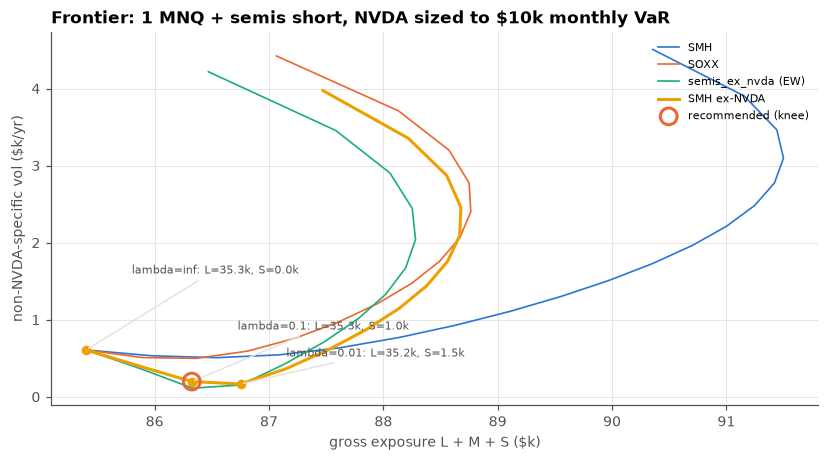

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.4))
for (k, frk), c in zip(FR.items(), PALETTE):
    seg = frk[frk.S <= 20_000]
    ax.plot(seg.gross / 1e3, seg.other_vol / 1e3, color=c, lw=2 if k == REC else 1.1,
            label=k)
for i, (lam, r) in enumerate(pts.iterrows()):
    ax.scatter(r.gross / 1e3, r.other_vol / 1e3, color=PALETTE[3], s=28, zorder=3)
    lab = "inf" if np.isinf(lam) else f"{lam:g}"
    ax.annotate(f"lambda={lab}: L={r.L / 1e3:.1f}k, S={r.S / 1e3:.1f}k",
                (r.gross / 1e3, r.other_vol / 1e3), xytext=(30, 18 + 16 * i),
                textcoords="offset points", fontsize=7, color=INK2,
                arrowprops={"arrowstyle": "-", "color": GRID})
kn = pick(fr, KNEE_LAM[REC])
ax.scatter(kn.gross / 1e3, kn.other_vol / 1e3, s=120, facecolors="none",
           edgecolors=PALETTE[1], lw=2, zorder=4, label="recommended (knee)")
ax.set_xlabel(r"gross exposure L + M + S (\$k)")
ax.set_ylabel(r"non-NVDA-specific vol (\$k/yr)")
ax.set_title(r"Frontier: 1 MNQ + semis short, NVDA sized to \$10k monthly VaR")
ax.legend(fontsize=7, loc="upper right")
save(fig, "05_frontier")

## 3. Recommended book today: capital and carry

NVDA in cash. Capital = `L` cash (+ the NVDA buy-back for the ex-NVDA leg) + MNQ
initial margin + 50% of the shares shorted (Reg T).

In [7]:
rf_now = 252 * rf.iloc[-5:].mean()
yfr = pd.read_parquet(load.raw_dir("free") / "yfinance.parquet")
yr = yfr[yfr.date > yfr.date.max() - pd.DateOffset(years=1)]
dy = yr.groupby("ticker").dividends.sum() / yfr.sort_values("date").groupby("ticker").close.last()
dy_leg = {"SMH": dy.SMH, "SOXX": dy.SOXX, "semis_ex_nvda (EW)": dy[semis_names].mean(),
          "SMH ex-NVDA": dy.SMH}
q_ndx = dy.QQQ + QQQ_ER
w_smh = w_nv.SMH.dropna().iat[-1]
cap = {}
for k in LEGS:
    p = pick(FR[k], KNEE_LAM[k])
    L, S = p.L, p.S
    w = w_smh if k == "SMH ex-NVDA" else 0.0
    short_px = S / (1 - w)
    buy = w * short_px
    fee_now = (fees.SMH if "SMH" in k else fees.SOXX if k == "SOXX"
               else fees[semis_names].mean(axis=1)).iloc[-21:].mean()
    u = (L * xn - C_now * f - S * LEGS[k]["x"]).dropna() / L
    sd_ew = u.ewm(alpha=0.06).std().iat[-1]              # same EWMA as the sizing
    c = {"L NVDA": L, "S semis (exposure)": S, "shares shorted $": short_px,
         "gross": L + buy + C_now + short_px, "net": L + buy - C_now - short_px,
         "monthly VaR EWMA": hg.Z99 * sd_ew * np.sqrt(M) * L,
         "monthly VaR hist": hg.hist_var(u.rolling(M).sum()) * L,
         "capital: NVDA cash": L + buy, "capital: MNQ margin": IM,
         "capital: Reg T 50% of short": 0.5 * short_px}
    c["capital total"] = c["capital: NVDA cash"] + IM + c["capital: Reg T 50% of short"]
    c["borrow fee bp"] = 1e4 * fee_now
    c["carry: borrow fee"] = -fee_now * short_px
    c["carry: interest on short collateral"] = rf_now * 1.5 * short_px
    c["carry: dividends (NVDA - semis)"] = dy.NVDA * (L + buy) - dy_leg[k] * short_px
    c["carry: MNQ basis (r - q)"] = (rf_now - q_ndx) * C_now
    c["carry: T-bill forgone on cash"] = -rf_now * (L + buy)
    c["net carry, with rebate"] = sum(v for kk, v in c.items() if kk.startswith("carry"))
    c["net carry, no rebate"] = c["net carry, with rebate"] - \
        c["carry: interest on short collateral"]
    cap[k] = c
u0 = (p0.L * xn - C_now * f).dropna() / p0.L
cap["none (04, VaR-sized)"] = {
    "L NVDA": p0.L, "S semis (exposure)": 0, "shares shorted $": 0, "gross": p0.L + C_now,
    "net": p0.L - C_now,
    "monthly VaR EWMA": hg.Z99 * u0.ewm(alpha=0.06).std().iat[-1] * np.sqrt(M) * p0.L,
    "monthly VaR hist": hg.hist_var(u0.rolling(M).sum()) * p0.L,
    "capital: NVDA cash": p0.L, "capital: MNQ margin": IM, "capital: Reg T 50% of short": 0,
    "capital total": p0.L + IM, "carry: MNQ basis (r - q)": (rf_now - q_ndx) * C_now,
    "carry: T-bill forgone on cash": -rf_now * p0.L,
    "carry: dividends (NVDA - semis)": dy.NVDA * p0.L}
cap["none (04, VaR-sized)"]["net carry, with rebate"] = sum(
    v for kk, v in cap["none (04, VaR-sized)"].items() if kk.startswith("carry"))
cap["none (04, VaR-sized)"]["net carry, no rebate"] = \
    cap["none (04, VaR-sized)"]["net carry, with rebate"]
CAP = pd.DataFrame(cap)
CAP.style.format("{:,.0f}", na_rep="")

,SMH,SOXX,semis_ex_nvda (EW),SMH ex-NVDA,"none (04, VaR-sized)"
L NVDA,"35,421","35,337","35,274","35,267","35,341"
S semis (exposure),500,500,"1,000","1,000",0
shares shorted $,500,500,"1,000","1,244",0
gross,"85,979","85,895","86,331","86,813","85,399"
net,"-15,137","-15,221","-15,784","-15,791","-14,717"
monthly VaR EWMA,"10,000","10,000","10,000","10,000","10,000"
monthly VaR hist,"5,924","5,901","5,871","5,860","5,965"
capital: NVDA cash,"35,421","35,337","35,274","35,511","35,341"
capital: MNQ margin,"3,630","3,630","3,630","3,630","3,630"
capital: Reg T 50% of short,250,250,500,622,0


Past ~\$2k, more semis short *adds* non-NVDA risk (the curves turn up and right) and
shrinks `L`.

## 4. Backtest 2020 to now: knee lambda vs lambda = inf

Hold **1 MNQ**. Each month, rebuild the covariances, size `L` to the \$10k EWMA VaR, and
pick `S` with the same `lambda` (each leg's knee from today). `lambda = inf` is the
04 book with VaR sizing. The 04 book as specified there (`L` = notional / h) is shown
for reference. Costs are as in 04, plus the Markit fee on the semis short.

In [8]:
mstarts = pd.Series(ret.index, index=ret.index).groupby(ret.index.to_period("M")).head(1)
mstarts = mstarts[mstarts.index >= pd.Timestamp("2020-01-01")]


def plan(k, lam):
    rows = {}
    for d in mstarts.index:
        prev = ret.index[ret.index.get_loc(d) - 1]
        p = pick(frontier(k, prev, C_t.loc[d]), lam)
        rows[d] = (p.L, p.S)
    return pd.DataFrame(rows, index=["L", "S"]).T


def run_plan(k, P):
    idx = ret.index[ret.index >= P.index[0]]
    L_d = P.L.reindex(idx).ffill()
    S_d = P.S.reindex(idx).ffill()
    N_d = C_t.reindex(idx)
    rolls = {d for d in P.index if d.month in (3, 6, 9, 12) and d != P.index[0]}

    def cost_fut(pL, pS, tL, tS, d):
        c = TCOST_STOCK * abs(tL - pL) + (COMM + TICK if pS == 0 else 0)
        return c + (2 * COMM + TICK if d in rolls else 0)
    a = hg.monthly_reset_backtest(xn, ret.NVDA, f, f, L_d, N_d, cost_fut)
    leg = LEGS[k]
    b = hg.monthly_reset_backtest(
        pd.Series(0.0, ret.index), pd.Series(0.0, ret.index),
        (leg["x"] + leg["fee"] / ANN).fillna(0), leg["r"].fillna(0), pd.Series(0.0, idx),
        S_d, lambda pL, pS, tL, tS, d: TCOST_STOCK * abs(tS - pS))
    return pd.DataFrame({"pnl": a.pnl.add(b.pnl, fill_value=0), "L": a.long, "S": b.short})


BT = {"lambda=inf (1 MNQ only, VaR-sized)": run_plan(REC, plan(REC, np.inf))}
for k in LEGS:
    BT[f"knee: 1 MNQ + {k} (lambda={KNEE_LAM[k]:g})"] = run_plan(k, plan(k, KNEE_LAM[k]))
h_ = (0.5 * hg.rolling_beta(xn, f, 252) + 0.5 * (xn.expanding(252).cov(f)
                                                   / f.expanding(252).var()))
P04 = pd.DataFrame({"L": (C_t / hg.hold_monthly(h_)).loc[mstarts.index], "S": 0.0})
BT["04 book (L = notional / h)"] = run_plan(REC, P04)

semis_f = s_clean - hg.rolling_beta(s_clean, f, 252).shift(1) * f   # semis ex NDX
rows = {}
for k, v in BT.items():
    s = hg.perf_stats(v.pnl, equity=1.0)
    u = v.pnl / v.L
    rows[k] = {"Sharpe": s["Sharpe"], "annual P&L $": s["annual P&L $"],
               "vol $/yr": s["vol $/yr"], "max drawdown $": s["max drawdown $"],
               "worst month $": s["worst month $"], "worst month": s["worst month"],
               "avg L": v.L.mean(), "avg S": v.S.mean(),
               "avg gross": (v.L + C_t.reindex(v.index) + v.S).mean(),
               "corr(book, semis factor)": u.corr(semis_f.reindex(u.index))}
PERF = pd.DataFrame(rows).T
print(f"{BT[next(iter(BT))].index[0].date()} to {ret.index[-1].date()}")
PERF

2020-01-02 to 2026-11-20


,Sharpe,annual P&L $,vol $/yr,max drawdown $,worst month $,worst month,avg L,avg S,avg gross,"corr(book, semis factor)"
"lambda=inf (1 MNQ only, VaR-sized)",1.09,"19,169.79","17,550.59","-27,396.21","-20,137.50",2026-11,"44,561.96",0.00,"78,815.00",0.19
knee: 1 MNQ + SMH (lambda=0.03),0.77,"13,893.97","18,012.05","-48,829.94","-15,357.59",2026-11,"61,240.56","45,952.80","141,446.40",-0.08
knee: 1 MNQ + SOXX (lambda=0.01),0.82,"14,863.37","18,187.59","-48,748.65","-15,196.10",2026-11,"58,034.93","43,002.99","135,290.96",-0.08
knee: 1 MNQ + semis_ex_nvda (EW) (lambda=0),0.66,"11,906.61","18,158.92","-57,313.27","-17,916.37",2026-04,"56,109.40","42,701.59","133,064.03",-0.18
knee: 1 MNQ + SMH ex-NVDA (lambda=0.03),0.74,"13,357.72","17,950.78","-49,968.90","-14,712.82",2026-11,"54,887.98","41,309.80","130,450.82",-0.09
04 book (L = notional / h),0.60,"4,146.72","6,867.74","-13,496.46","-8,153.90",2026-11,"20,757.34",0.00,"55,010.38",0.25


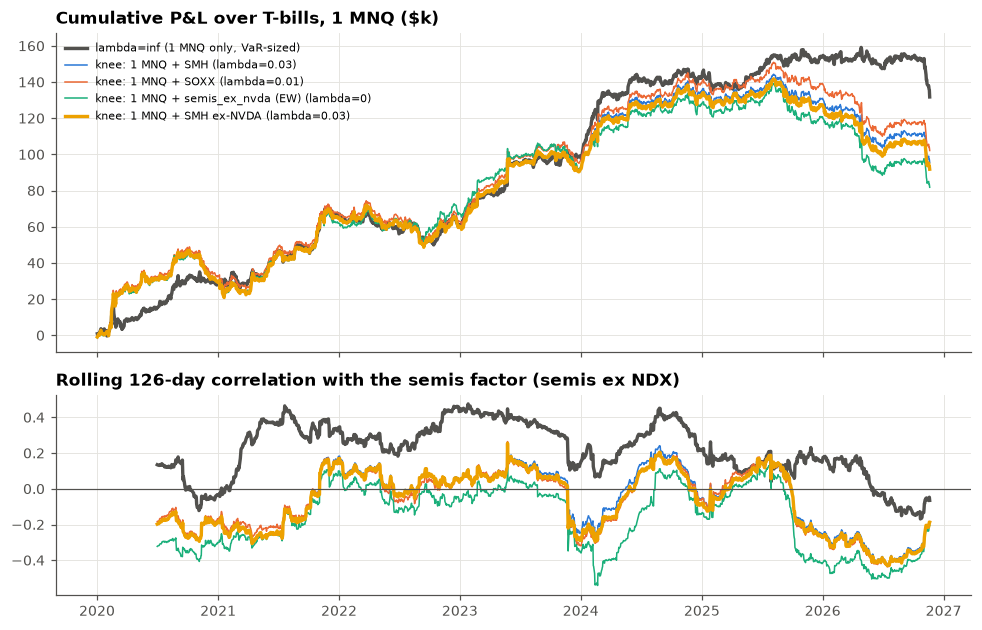

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(9, 5.8), sharex=True,
                         gridspec_kw={"height_ratios": [1.6, 1]})
cols = dict(zip(BT, [INK2] + PALETTE))
for k, v in BT.items():
    if k.startswith("04 book"):
        continue
    lw = 2.2 if (REC in k or k.startswith("lambda")) else 1.0
    axes[0].plot(v.index, v.pnl.cumsum() / 1e3, color=cols[k], lw=lw, label=k)
    rc = (v.pnl / v.L).rolling(126).corr(semis_f.reindex(v.index))
    axes[1].plot(rc.index, rc, color=cols[k], lw=lw)
axes[0].set_title(r"Cumulative P&L over T-bills, 1 MNQ (\$k)")
axes[0].legend(fontsize=7, loc="upper left")
axes[1].axhline(0, color=INK2, lw=0.8)
axes[1].set_title("Rolling 126-day correlation with the semis factor (semis ex NDX)")
fig.tight_layout()
save(fig, "05_backtest")

## 5. Bottom line

The semis overlay is a good idea only when NVDA's semis beta net of NDX is clearly
positive. Today it isn't (about 0 over 1-2 years), so it adds gross and borrow without
removing risk, and in the backtest it cost Sharpe. Hold **1 MNQ against about \$35k of
NVDA in cash, with no semis short**. If you add one later, use **SMH ex-NVDA** (short
SMH and buy back its ~20% NVDA slice), at a size set by this frontier. Revisit monthly:
the trigger is the trailing-252d semis beta (section 1) rising above about 0.3.